In [1]:
# Importing necessary classes 
import math
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
import tensorflow as tf
import seaborn as sn

def safe_mape(y_true, y_pred, min_actual=0.1):
    """Mean absolute percentage error, computed only on days with at
    least min_actual inches of observed rain, since dividing by a near
    zero actual value produces a huge or undefined percentage."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    pct_errors = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    return float(np.mean(pct_errors) * 100.0), int(mask.sum())

In [2]:
# Loading the dataset and shaping it into a time series dataset
rainfall= pd.read_csv('2619492.csv')
rainfall[["DATE"]] = rainfall[["DATE"]].apply(lambda c: pd.to_datetime(c, dayfirst=True))
rainfall = rainfall.set_index('DATE')
rainfall.head(3)

,PRCP
DATE,
1990-01-01,0.0
1990-01-02,0.0
1990-01-03,0.0


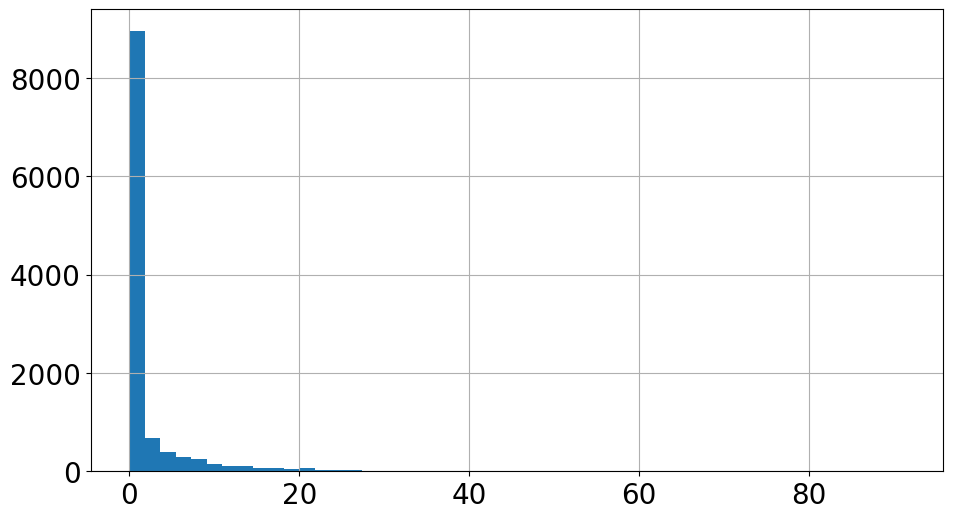

In [3]:
#Plotting the histogram of dataset
plt.figure(figsize=(11, 6))
plt.rc('font', size=20)         # controls default text sizes
plt.rc('axes', titlesize=22)    # fontsize of the axes title
plt.rc('axes', labelsize=22)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)  # fontsize of the tick labels
plt.rc('legend', fontsize=22)   # legend fontsize
plt.rc('figure', titlesize=23)  # fontsize of the figure title
series = rainfall.PRCP
series.hist(bins=50)
plt.show()

In [4]:
# Box-Cox Transformation Function
def boxcox1p(data):
  p1data= data+1
  bcdata, bclambda = boxcox(p1data)
  return bcdata, bclambda

In [5]:
# Inverse Box-Cox transformation Function
def inv_boxcox1p(bcdata, bclambda):
  data=inv_boxcox(bcdata, bclambda)-1
  return data

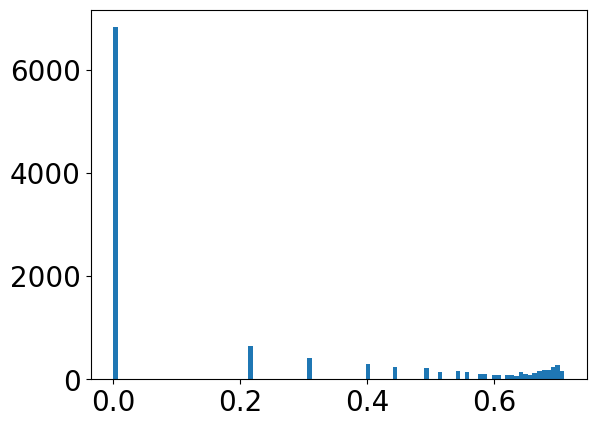

In [6]:
#Calling the Box-Cox transformation function to normalize the data distribution
inv_data, lam_value = boxcox1p(rainfall.PRCP) 
plt.hist(inv_data, bins=100)
plt.show()

In [7]:
#Scaling the data for better results 
scaler= MinMaxScaler(feature_range=(0,1))
data = inv_data.reshape(-1,1)
scaler.fit(data)
rain_data = scaler.transform(data)[:,0]

In [8]:
#Function for making windowed dataset
from numpy import array
def split_sequences(series, window):
  x, y= list(), list()
  for i in range(len(series)):
    end= i+ window
    if end>len(series)-1:
      break
    seq_x, seq_y= series[i:end], series[end]
    x.append(seq_x)
    y.append(seq_y)
  return array(x), array(y)

In [9]:
#Dividing the dataset into train and test subsets
new_Data = rain_data
window_size = 70
train = new_Data[0:9058]
test = new_Data[9058:]
x_train, y_train = split_sequences(train, window_size)
x_test, y_test = split_sequences(test, window_size)

In [10]:
#Reshaping the test and test input data for LSTM model
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [11]:
# Building the LSTM model
model = Sequential()
model.add(LSTM(32, input_shape=(window_size, 1), return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(32,))
model.add(Dropout(0.5))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='relu'))

C:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: 1e-7 * 10**(epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-7, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mean_squared_error"])
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

None


In [13]:
# LSTM model training phase 
print("Starting to fit")
history = model.fit(x_train, y_train, epochs=100, batch_size=60, verbose=1, validation_data=(x_train, y_train), callbacks=[lr_schedule])

Starting to fit
Epoch 1/100



  1/150 ━━━━━━━━━━━━━━━━━━━━ 5:53 2s/step - loss: 0.1022 - mean_squared_error: 0.2044


  4/150 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.1104 - mean_squared_error: 0.2207


  6/150 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.1131 - mean_squared_error: 0.2262


  9/150 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.1149 - mean_squared_error: 0.2299

...


144/150 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0764 - mean_squared_error: 0.1528


146/150 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0764 - mean_squared_error: 0.1528


148/150 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0764 - mean_squared_error: 0.1528


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0764 - mean_squared_error: 0.1528


150/150 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - loss: 0.0764 - mean_squared_error: 0.1529 - val_loss: 0.0756 - val_mean_squared_error: 0.1512 - learning_rate: 2.9854e-05


In [14]:
model.evaluate(x_test, y_test)


 1/69 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.0545 - mean_squared_error: 0.1091


 7/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0574 - mean_squared_error: 0.1147


13/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0624 - mean_squared_error: 0.1248


19/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0660 - mean_squared_error: 0.1319


25/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0683 - mean_squared_error: 0.1366

...


54/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0744 - mean_squared_error: 0.1488


59/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0749 - mean_squared_error: 0.1498


65/69 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0754 - mean_squared_error: 0.1509


69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0806 - mean_squared_error: 0.1612


[0.08057727664709091, 0.16115455329418182]

In [15]:
#Predicting the values for test set
result= model.predict(x_test)
result= scaler.inverse_transform(result)
result= inv_boxcox1p(result, lam_value)[:, 0]

y_test_orig= scaler.inverse_transform(y_test.reshape(-1, 1))
y_test_orig= inv_boxcox1p(y_test_orig, lam_value)[:, 0]

score= math.sqrt(mean_squared_error(y_test_orig, result))
mae= mean_absolute_error(y_test_orig, result)
mape, mape_n= safe_mape(y_test_orig, result)

print(f"RMSE: {score:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"MAPE: {mape:.2f}% (computed on {mape_n} days with >= 0.1 in of rain)")
score


 1/69 ━━━━━━━━━━━━━━━━━━━━ 19s 286ms/step


 8/69 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step   


15/69 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


21/69 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


27/69 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

...


63/69 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


RMSE: 6.2009
MAE:  2.3244
MAPE: 81.10% (computed on 919 days with >= 0.1 in of rain)


6.200875603465376

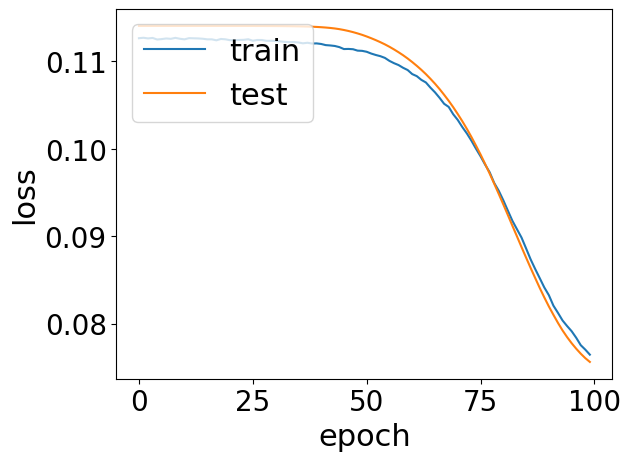

In [16]:
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [17]:
#Defining average and naive forecast functions
def naiveForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = x_data[:,-1,0]
    return forecast

def avgForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = np.mean(x_data[:,:,0], axis=1)
    return forecast

naive_forecast = naiveForecast(x_test)
avg_forecast = avgForecast(x_test)

In [18]:
avg_forecast= scaler.inverse_transform(avg_forecast.reshape(-1,1))[:,0]
avg_forecast = inv_boxcox1p(avg_forecast, lam_value)
naive_forecast= scaler.inverse_transform(naive_forecast.reshape(-1,1))[:,0]
naive_forecast = inv_boxcox1p(naive_forecast, lam_value)

In [19]:
rmse_avg= math.sqrt(mean_squared_error(y_test_orig, avg_forecast))
rmse_naive= math.sqrt(mean_squared_error(y_test_orig, naive_forecast))

In [20]:
rmse_avg

6.1667408980884755

In [21]:
rmse_naive

7.96920668104952